# 実験2 (論文 第5〜6章): 記憶制限・メモリレス MoQ 手法による省メモリ高速化とスケーラビリティ解析

博士論文 第5章 (LQN / LNAQ / LMoQ) および 第6章 (CG / MLQN / MLNAQ / MLMoQ) の再現実験を行う．

- **数値等価性検証**: PyTorch `LimitedMemoryMoQOptimizer`・`MemoryLessMoQOptimizer` と GPU バッチエンジンの一致確認
- **理論スケーリング解析**: 表6, 表13, 表17 に基づく計算量 $\mathcal{O}(md)$・$\mathcal{O}(d)$ とメモリ消費量の比較
- **実験 2A (1次元関数 $f(x)$ 近似, 式(124))**: `1-10-1` ($d=31$, $|T_r|=400$, $|T_e|=10,000$, $R=10$ 試行) における履歴数 $m \in \{4,8,16,32\}$ の影響
- **実験 2B (5次元 Levy 関数近似, 式(102))**: `5-50-1` ($d=351$, $|T_r|=5,000$, $|T_e|=2,500$, $R=10$ 試行)

In [1]:
import os
import sys
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
os.environ.setdefault('MPLCONFIGDIR', os.path.join(os.getcwd(), '.mplconfig'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from model import FeedforwardMLP, BatchedMLP, half_mse_loss
from utils import (
    setup_japanese_matplotlib,
    compute_theoretical_cost_and_storage,
    LimitedMemoryMoQOptimizer,
    MemoryLessMoQOptimizer,
    target_function_1d,
    load_or_create_1d_f1_dataset,
    load_or_create_levy_5d_dataset,
    generate_initial_weights,
    run_limited_or_memoryless_batched,
    format_ex2_dataframe,
)

setup_japanese_matplotlib()
os.makedirs('../report/img', exist_ok=True)
os.makedirs('../datasets', exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch: {torch.__version__}, Device: {device}')

PyTorch: 2.7.1+cu118, Device: cuda


## 1. `LimitedMemoryMoQOptimizer`・`MemoryLessMoQOptimizer` と並列バッチエンジンの数値等価性検証

In [2]:
torch.manual_seed(2023)
X_chk = torch.rand((64, 2), dtype=torch.float64, device=device) * 2.0 - 1.0
D_chk = torch.sin(X_chk[:, :1]) * X_chk[:, 1:2]
w_chk = generate_initial_weights(1, 2 * 10 + 10 + 10 * 1 + 1, seed=202, device=device)

eq_rows = []
for algo in ('LQN', 'LNAQ', 'LMoQ', 'CG', 'MLQN', 'MLNAQ', 'MLMoQ'):
    row = {'Algorithm': algo}
    for k_step in (5, 10):
        res_b = run_limited_or_memoryless_batched(
            algo=algo, w_init=w_chk, X_train=X_chk, XT_train=X_chk.t().contiguous(),
            D_train=D_chk, X_test=X_chk, D_test=D_chk, n_in=2, n_hid=10,
            memory_size=4, use_adaptive_mu=True, max_epochs=k_step, show_pbar=False
        )
        net = FeedforwardMLP(2, 10, 1, dtype=torch.float64).to(device)
        net.set_flat_params(w_chk[0])
        if algo in ('LQN', 'LNAQ', 'LMoQ'):
            opt = LimitedMemoryMoQOptimizer(net.parameters(), algo=algo, memory_size=4, use_adaptive_mu=True)
        else:
            opt = MemoryLessMoQOptimizer(net.parameters(), algo=algo, use_adaptive_mu=True)
        def closure(backward=True):
            opt.zero_grad()
            out = net(X_chk)
            loss = half_mse_loss(out, D_chk)
            if backward:
                loss.backward()
            return loss
        for _ in range(k_step):
            opt.step(closure)
        diff = float(torch.max(torch.abs(res_b['best_weights'] - net.get_flat_params())).item())
        row[f'Max |w diff| (k={k_step})'] = f'{diff:.3e}'
    eq_rows.append(row)

pd.DataFrame(eq_rows)

,Algorithm,Max |w diff| (k=5),Max |w diff| (k=10)
0,LQN,2.665e-15,1.016e-14
1,LNAQ,2.609e-15,8.882e-16
2,LMoQ,2.665e-15,1.277e-15
3,CG,2.220e-16,2.220e-16
4,MLQN,1.810e-14,2.996e-12
5,MLNAQ,1.704e-14,1.454e-14
6,MLMoQ,1.801e-14,1.582e-14


## 2. 理論計算コストとメモリ消費量のスケーリング比較 (表6, 表13, 表17)

     d    MoQ_cost  LMoQ_m4_cost  MLMoQ_cost     MoQ_mem  LMoQ_m4_mem  MLMoQ_mem
    31       62961         62558       62124       94023        93310      93062
   221      490841        445978      442884      712283       665210     663442
   351      825201        708318      703404     1176903      1056510    1053702
   750     2062500       1513500     1503000     2814000      2257500    2251500
  7960    79281600      16063280    15951840    87257520     23959600   23895920
100000 10200000000     201800000   200400000 10300200000    301000000  300200000


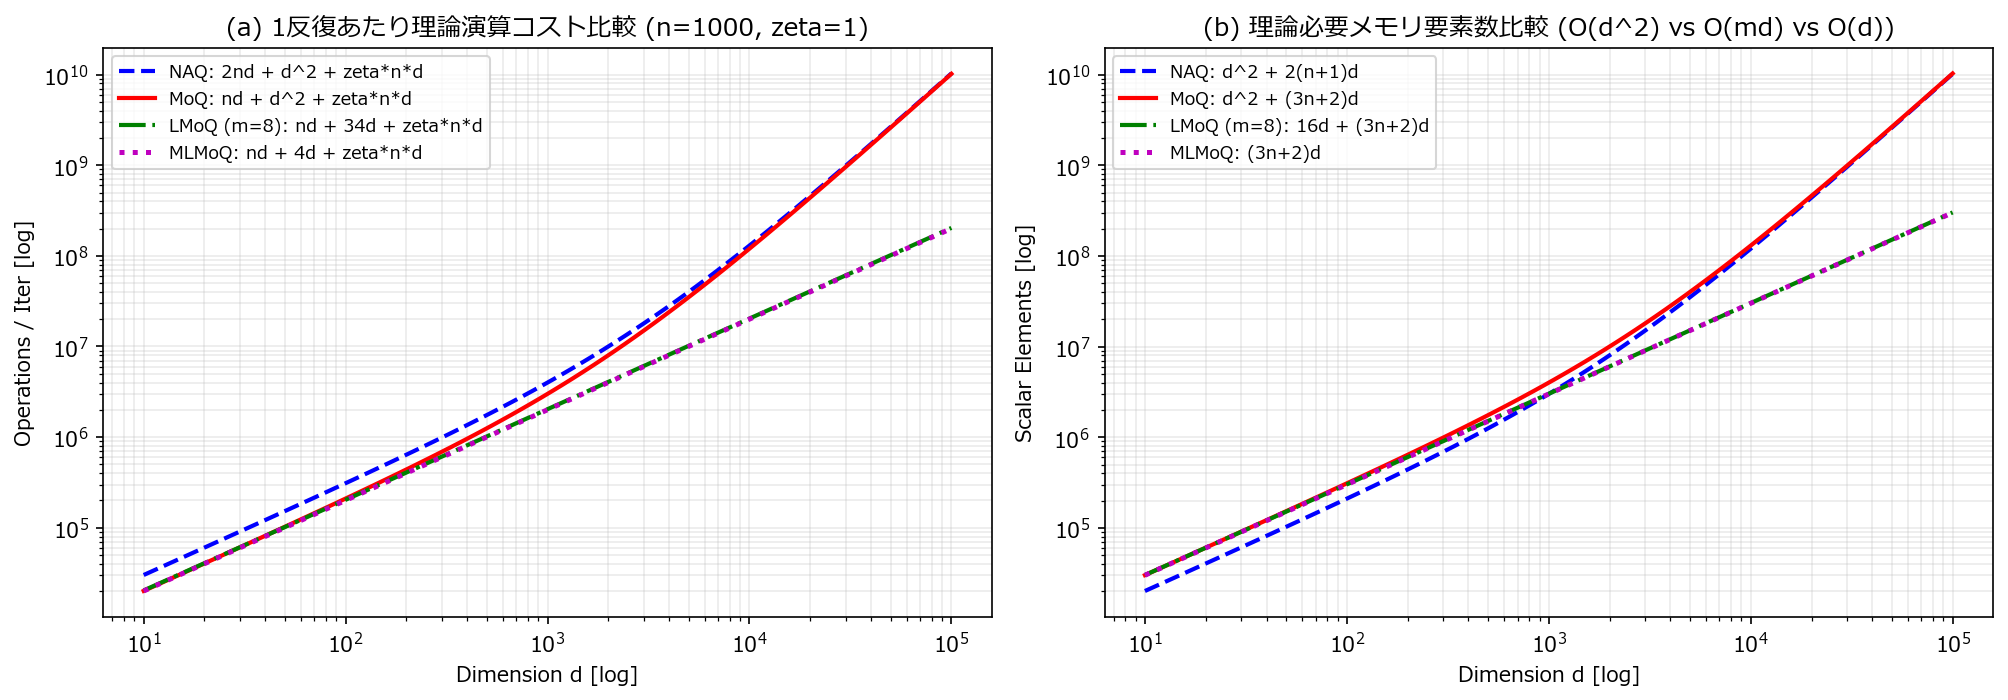

In [3]:
df_theory = compute_theoretical_cost_and_storage(
    np.array([31, 221, 351, 750, 7960, 100000]), n=1000, zeta=1, m_list=(4, 16)
)
print(df_theory[['d', 'MoQ_cost', 'LMoQ_m4_cost', 'MLMoQ_cost', 'MoQ_mem', 'LMoQ_m4_mem', 'MLMoQ_mem']].to_string(index=False))

d_curve = np.logspace(1, 5, 80).astype(int)
df_c = compute_theoretical_cost_and_storage(d_curve, n=1000, zeta=1, m_list=(8, 32))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ax = axes[0]
ax.loglog(df_c['d'], df_c['NAQ_cost'], 'b--', linewidth=2.0, label='NAQ: 2nd + d^2 + zeta*n*d')
ax.loglog(df_c['d'], df_c['MoQ_cost'], 'r-', linewidth=2.0, label='MoQ: nd + d^2 + zeta*n*d')
ax.loglog(df_c['d'], df_c['LMoQ_m8_cost'], 'g-.', linewidth=2.0, label='LMoQ (m=8): nd + 34d + zeta*n*d')
ax.loglog(df_c['d'], df_c['MLMoQ_cost'], 'm:', linewidth=2.4, label='MLMoQ: nd + 4d + zeta*n*d')
ax.set_title('(a) 1反復あたり理論演算コスト比較 (n=1000, zeta=1)')
ax.set_xlabel('Dimension d [log]'); ax.set_ylabel('Operations / Iter [log]')
ax.legend(fontsize=8.5); ax.grid(alpha=0.25, which='both')

ax = axes[1]
ax.loglog(df_c['d'], df_c['NAQ_mem'], 'b--', linewidth=2.0, label='NAQ: d^2 + 2(n+1)d')
ax.loglog(df_c['d'], df_c['MoQ_mem'], 'r-', linewidth=2.0, label='MoQ: d^2 + (3n+2)d')
ax.loglog(df_c['d'], df_c['LMoQ_m8_mem'], 'g-.', linewidth=2.0, label='LMoQ (m=8): 16d + (3n+2)d')
ax.loglog(df_c['d'], df_c['MLMoQ_mem'], 'm:', linewidth=2.4, label='MLMoQ: (3n+2)d')
ax.set_title('(b) 理論必要メモリ要素数比較 (O(d^2) vs O(md) vs O(d))')
ax.set_xlabel('Dimension d [log]'); ax.set_ylabel('Scalar Elements [log]')
ax.legend(fontsize=8.5); ax.grid(alpha=0.25, which='both')

plt.tight_layout()
plt.savefig('../report/img/ex002_complexity_scaling.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. 実験 2A: 1次元非線形関数 $f(x)$ の近似 (`1-10-1`, $d=31$, $|T_r|=400$, $|T_e|=10,000$, $R=10$)

In [4]:
ds_1d = load_or_create_1d_f1_dataset(dataset_dir='../datasets', seed=2023, device=device)
print(f"1D Train: {tuple(ds_1d['X_train_64'].shape)}, Test: {tuple(ds_1d['X_test_64'].shape)}")

n_in_2a, n_hid_2a = 1, 10
d_w_2a = n_in_2a * n_hid_2a + n_hid_2a + n_hid_2a * 1 + 1  # 31
R = 10
w_init_2a = generate_initial_weights(R, d_w_2a, seed=2023, device=device)

res_2a_list = []
res_2a_map = {}

for algo in ('LQN', 'LNAQ', 'LMoQ'):
    for m in (4, 8, 16, 32):
        r = run_limited_or_memoryless_batched(
            algo=algo, w_init=w_init_2a,
            X_train=ds_1d['X_train_64'], XT_train=ds_1d['XT_train_64'], D_train=ds_1d['D_train_64'],
            X_test=ds_1d['X_test_64'], D_test=ds_1d['D_test_64'],
            n_in=n_in_2a, n_hid=n_hid_2a, memory_size=m, use_adaptive_mu=True,
            max_epochs=3000, record_stride=100, show_pbar=False
        )
        res_2a_list.append(r)
        res_2a_map[f'{algo}_m{m}'] = r
        print(f"{algo:5s} m={m:2d} | E_tr_med={r['train_median']:.4f} | E_te_med={r['test_median']:.4f} | Iters={r['ave_epochs']:.1f} | Conv={r['conv_rate']:.1f}%")

for algo in ('CG', 'MLQN', 'MLNAQ', 'MLMoQ'):
    r = run_limited_or_memoryless_batched(
        algo=algo, w_init=w_init_2a,
        X_train=ds_1d['X_train_64'], XT_train=ds_1d['XT_train_64'], D_train=ds_1d['D_train_64'],
        X_test=ds_1d['X_test_64'], D_test=ds_1d['D_test_64'],
        n_in=n_in_2a, n_hid=n_hid_2a, use_adaptive_mu=True,
        max_epochs=3000, record_stride=100, show_pbar=False
    )
    res_2a_list.append(r)
    res_2a_map[algo] = r
    print(f"{algo:5s}      | E_tr_med={r['train_median']:.4f} | E_te_med={r['test_median']:.4f} | Iters={r['ave_epochs']:.1f} | Conv={r['conv_rate']:.1f}%")

df_2a = format_ex2_dataframe(res_2a_list, precision=3)
df_2a.to_csv('../datasets/ex002_1d_results.csv', index=False, encoding='utf-8')
df_2a

1D Train: (400, 1), Test: (10000, 1)
LQN   m= 4 | E_tr_med=4.8828 | E_te_med=4.9078 | Iters=3000.0 | Conv=0.0%
LQN   m= 8 | E_tr_med=8.8378 | E_te_med=8.8778 | Iters=3000.0 | Conv=20.0%
LQN   m=16 | E_tr_med=5.1045 | E_te_med=5.3234 | Iters=3000.0 | Conv=20.0%
LQN   m=32 | E_tr_med=1.5803 | E_te_med=1.6063 | Iters=2650.0 | Conv=60.0%
LNAQ  m= 4 | E_tr_med=5.3646 | E_te_med=5.4845 | Iters=3000.0 | Conv=10.0%
LNAQ  m= 8 | E_tr_med=9.0883 | E_te_med=8.7579 | Iters=3000.0 | Conv=10.0%
LNAQ  m=16 | E_tr_med=6.6175 | E_te_med=6.5439 | Iters=3000.0 | Conv=10.0%
LNAQ  m=32 | E_tr_med=2.2414 | E_te_med=2.3113 | Iters=2830.0 | Conv=60.0%
LMoQ  m= 4 | E_tr_med=7.3105 | E_te_med=7.2452 | Iters=3000.0 | Conv=10.0%
LMoQ  m= 8 | E_tr_med=13.7907 | E_te_med=13.1850 | Iters=2960.0 | Conv=30.0%
LMoQ  m=16 | E_tr_med=4.8901 | E_te_med=5.2212 | Iters=3000.0 | Conv=40.0%
LMoQ  m=32 | E_tr_med=1.5964 | E_te_med=1.6232 | Iters=2830.0 | Conv=60.0%
CG         | E_tr_med=58.0954 | E_te_med=57.1589 | Iters=3000.

,Algorithm,m,E_train (x10^3) Med/Ave/Best/Worst,Est. Time(s),Per Iter(ms),Ave. Iters,E_test (x10^3) Med/Ave/Best/Worst,Conv(%)
0,LQN,4,4.883 / 8.586 / 1.717 / 33.449,0.758,0.2526,3000,4.908 / 8.612 / 1.705 / 34.247,0.0
1,LQN,8,8.838 / 10.115 / 0.873 / 20.089,0.902,0.3006,3000,8.878 / 9.849 / 0.862 / 19.001,20.0
2,LQN,16,5.105 / 8.272 / 0.476 / 18.879,1.286,0.4286,3000,5.323 / 8.023 / 0.485 / 17.786,20.0
3,LQN,32,1.580 / 4.713 / 0.359 / 18.485,2.133,0.8048,2650,1.606 / 4.476 / 0.360 / 17.400,60.0
4,LNAQ,4,5.365 / 9.487 / 0.348 / 27.576,0.825,0.2750,3000,5.485 / 9.493 / 0.349 / 28.671,10.0
5,LNAQ,8,9.088 / 11.627 / 0.243 / 32.686,1.019,0.3395,3000,8.758 / 11.322 / 0.242 / 33.507,10.0
6,LNAQ,16,6.618 / 10.364 / 1.181 / 24.019,1.443,0.4809,3000,6.544 / 10.285 / 1.200 / 24.852,10.0
7,LNAQ,32,2.241 / 5.756 / 0.032 / 21.126,2.274,0.8036,2830,2.311 / 5.675 / 0.035 / 21.614,60.0
8,LMoQ,4,7.310 / 8.943 / 0.967 / 20.056,0.823,0.2743,3000,7.245 / 8.599 / 1.020 / 18.953,10.0
9,LMoQ,8,13.791 / 14.209 / 0.493 / 29.528,1.036,0.3500,2960,13.185 / 14.161 / 0.502 / 29.403,30.0


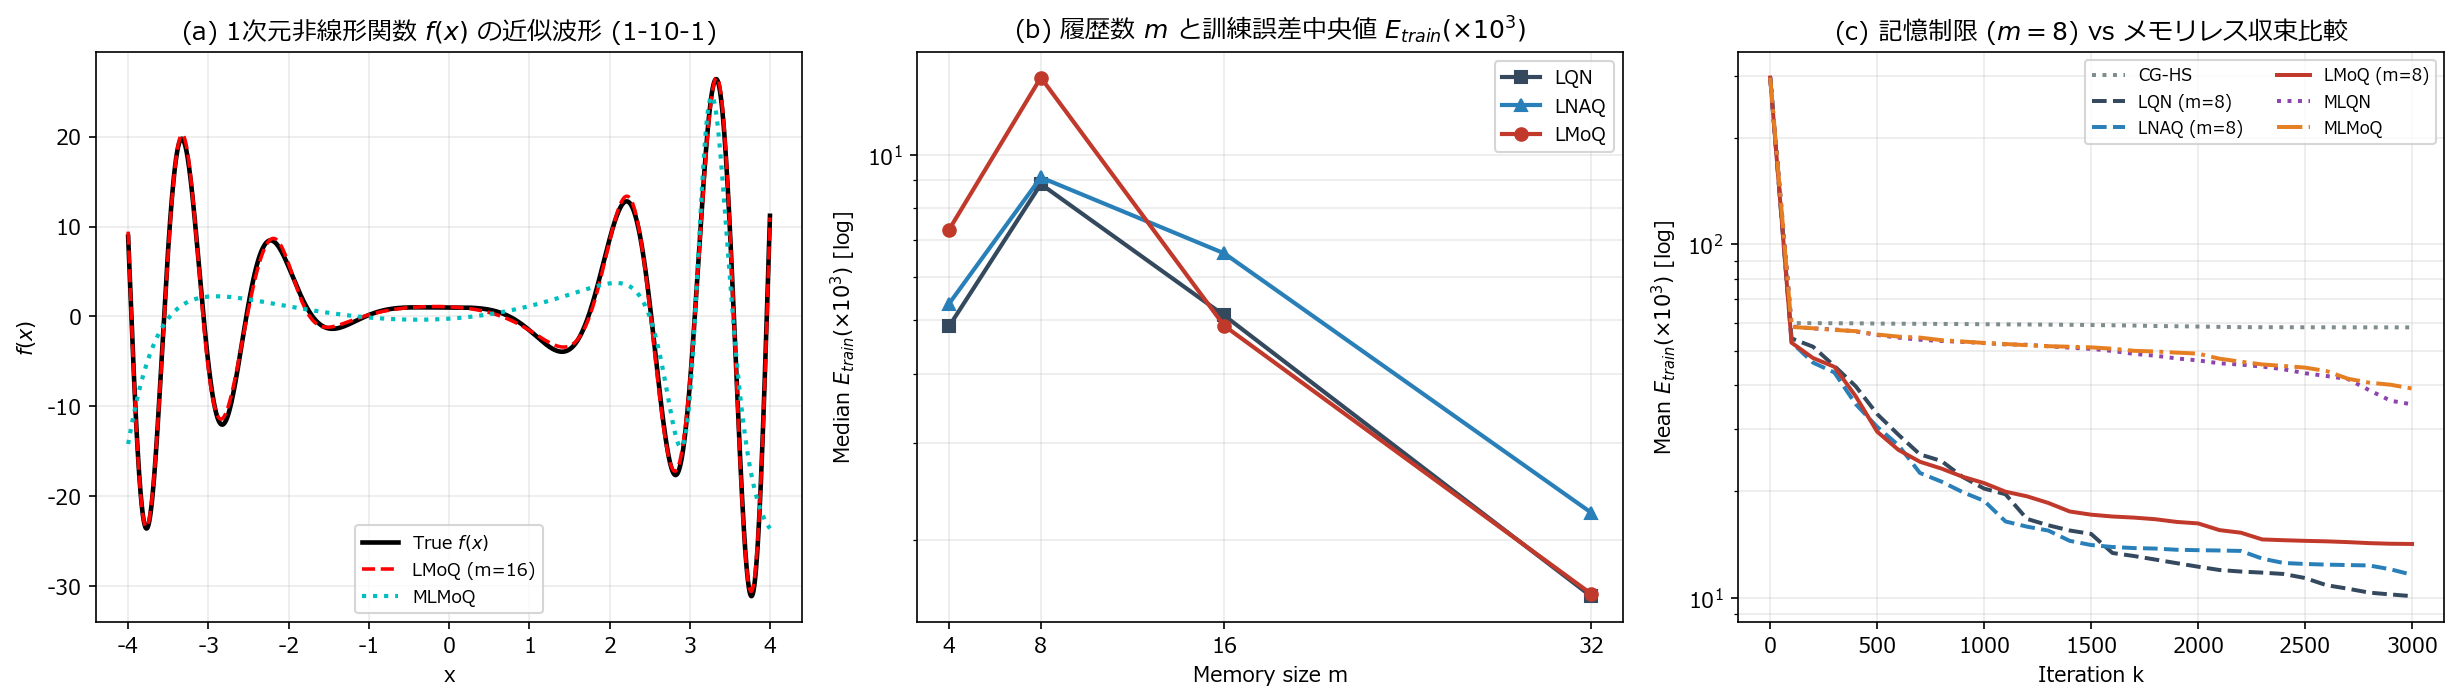

In [5]:
# 図2: 1次元関数 f(x) の近似結果・記憶容量 m 依存性・収束曲線
stats = ds_1d['norm_stats']
x_min, x_max, y_min, y_max = stats['x_min'], stats['x_max'], stats['y_min'], stats['y_max']
bmlp_1d = BatchedMLP(n_in_2a, n_hid_2a, 1)
x_te_raw = ds_1d['x_te_raw']
y_te_raw = ds_1d['y_te_raw']

with torch.no_grad():
    yp_lmoq = bmlp_1d.predict(res_2a_map['LMoQ_m16']['best_weights'].unsqueeze(0), ds_1d['X_test_64']).squeeze(0).squeeze(-1).cpu().numpy()
    yp_mlmoq = bmlp_1d.predict(res_2a_map['MLMoQ']['best_weights'].unsqueeze(0), ds_1d['X_test_64']).squeeze(0).squeeze(-1).cpu().numpy()
yp_lmoq_raw = (yp_lmoq + 1.0) * 0.5 * (y_max - y_min) + y_min
yp_mlmoq_raw = (yp_mlmoq + 1.0) * 0.5 * (y_max - y_min) + y_min

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

ax = axes[0]
ax.plot(x_te_raw, y_te_raw, 'k-', linewidth=2.2, label='True $f(x)$')
ax.plot(x_te_raw, yp_lmoq_raw, 'r--', linewidth=1.7, label='LMoQ (m=16)')
ax.plot(x_te_raw, yp_mlmoq_raw, 'c:', linewidth=2.0, label='MLMoQ')
ax.set_title('(a) 1次元非線形関数 $f(x)$ の近似波形 (1-10-1)')
ax.set_xlabel('x'); ax.set_ylabel('$f(x)$')
ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

ax = axes[1]
m_vals = [4, 8, 16, 32]
for algo, col, marker in [('LQN', '#34495e', 's'), ('LNAQ', '#2980b9', '^'), ('LMoQ', '#c0392b', 'o')]:
    meds = [res_2a_map[f'{algo}_m{m}']['train_median'] for m in m_vals]
    ax.plot(m_vals, meds, marker=marker, linewidth=2.0, color=col, label=algo)
ax.set_yscale('log')
ax.set_xticks(m_vals)
ax.set_title('(b) 履歴数 $m$ と訓練誤差中央値 $E_{train} (\\times 10^3)$')
ax.set_xlabel('Memory size m'); ax.set_ylabel('Median $E_{train} (\\times 10^3)$ [log]')
ax.legend(fontsize=9); ax.grid(alpha=0.25, which='both')

ax = axes[2]
for key, lbl, col, ls in [
    ('CG', 'CG-HS', '#7f8c8d', ':'),
    ('LQN_m8', 'LQN (m=8)', '#34495e', '--'),
    ('LNAQ_m8', 'LNAQ (m=8)', '#2980b9', '--'),
    ('LMoQ_m8', 'LMoQ (m=8)', '#c0392b', '-'),
    ('MLQN', 'MLQN', '#8e44ad', ':'),
    ('MLMoQ', 'MLMoQ', '#e67e22', '-.'),
]:
    r = res_2a_map[key]
    ax.plot(r['rec_epochs'], np.clip(r['rec_means'] * 1e3, 1e-4, None), label=lbl, color=col, linestyle=ls, linewidth=1.9)
ax.set_yscale('log')
ax.set_title('(c) 記憶制限 ($m=8$) vs メモリレス収束比較')
ax.set_xlabel('Iteration k'); ax.set_ylabel('Mean $E_{train} (\\times 10^3)$ [log]')
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.25, which='both')

plt.tight_layout()
plt.savefig('../report/img/ex002_1d_memory_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. 実験 2B: 5次元 Levy 関数 (`5-50-1`, $d=351$, $R=10$) における LQN / LNAQ / LMoQ / メモリレス手法の比較

In [6]:
ds_levy = load_or_create_levy_5d_dataset(dataset_dir='../datasets', seed=2023, device=device)
n_in_2b, n_hid_2b = 5, 50
d_w_2b = n_in_2b * n_hid_2b + n_hid_2b + n_hid_2b * 1 + 1  # 351
w_init_2b = generate_initial_weights(R, d_w_2b, seed=2024, device=device)

configs_2b = [
    ('LQN', 8), ('LNAQ', 8), ('LMoQ', 8), ('LMoQ', 16), ('LMoQ', 32),
    ('CG', 1), ('MLQN', 1), ('MLNAQ', 1), ('MLMoQ', 1),
]
res_2b_list = []
res_2b_map = {}
for algo, m in configs_2b:
    r = run_limited_or_memoryless_batched(
        algo=algo, w_init=w_init_2b,
        X_train=ds_levy['X_train_64'], XT_train=ds_levy['XT_train_64'], D_train=ds_levy['D_train_64'],
        X_test=ds_levy['X_test_64'], D_test=ds_levy['D_test_64'],
        n_in=n_in_2b, n_hid=n_hid_2b, memory_size=m, use_adaptive_mu=True,
        max_epochs=3000, record_stride=100, show_pbar=False
    )
    res_2b_list.append(r)
    key = f'{algo}_m{m}' if algo in ('LQN', 'LNAQ', 'LMoQ') else algo
    res_2b_map[key] = r
    print(f"{key:10s} | E_tr_med={r['train_median']:.4f} | E_te_med={r['test_median']:.4f} | Time={r['ave_time_sec']:.3f}s | Conv={r['conv_rate']:.1f}%")

df_2b = format_ex2_dataframe(res_2b_list, precision=3)
df_2b.to_csv('../datasets/ex002_levy_memory_results.csv', index=False, encoding='utf-8')
df_2b

LQN_m8     | E_tr_med=15.1016 | E_te_med=17.1769 | Time=1.256s | Conv=0.0%
LNAQ_m8    | E_tr_med=15.0548 | E_te_med=17.2362 | Time=2.145s | Conv=0.0%
LMoQ_m8    | E_tr_med=15.0811 | E_te_med=17.2654 | Time=1.743s | Conv=0.0%
LMoQ_m16   | E_tr_med=14.7902 | E_te_med=17.5871 | Time=2.403s | Conv=0.0%
LMoQ_m32   | E_tr_med=14.4195 | E_te_med=18.0642 | Time=3.518s | Conv=0.0%
CG         | E_tr_med=16.0861 | E_te_med=16.7595 | Time=1.098s | Conv=0.0%
MLQN       | E_tr_med=15.7441 | E_te_med=16.7436 | Time=0.840s | Conv=0.0%
MLNAQ      | E_tr_med=15.7414 | E_te_med=16.7374 | Time=1.502s | Conv=0.0%
MLMoQ      | E_tr_med=15.7448 | E_te_med=16.7366 | Time=1.358s | Conv=0.0%


,Algorithm,m,E_train (x10^3) Med/Ave/Best/Worst,Est. Time(s),Per Iter(ms),Ave. Iters,E_test (x10^3) Med/Ave/Best/Worst,Conv(%)
0,LQN,8,15.102 / 15.081 / 14.946 / 15.233,1.256,0.4186,3000,17.177 / 17.236 / 17.074 / 17.613,0.0
1,LNAQ,8,15.055 / 15.059 / 14.972 / 15.213,2.145,0.7150,3000,17.236 / 17.249 / 16.998 / 17.479,0.0
2,LMoQ,8,15.081 / 15.077 / 14.962 / 15.157,1.743,0.5811,3000,17.265 / 17.233 / 17.029 / 17.436,0.0
3,LMoQ,16,14.790 / 14.789 / 14.546 / 14.962,2.403,0.8011,3000,17.587 / 17.595 / 17.350 / 17.799,0.0
4,LMoQ,32,14.419 / 14.404 / 14.311 / 14.448,3.518,1.1725,3000,18.064 / 18.070 / 17.700 / 18.378,0.0
5,CG,-,16.086 / 16.094 / 16.049 / 16.155,1.098,0.3658,3000,16.760 / 16.739 / 16.613 / 16.827,0.0
6,MLQN,-,15.744 / 15.744 / 15.719 / 15.763,0.840,0.2800,3000,16.744 / 16.740 / 16.691 / 16.806,0.0
7,MLNAQ,-,15.741 / 15.743 / 15.721 / 15.785,1.502,0.5006,3000,16.737 / 16.729 / 16.680 / 16.766,0.0
8,MLMoQ,-,15.745 / 15.742 / 15.689 / 15.790,1.358,0.4526,3000,16.737 / 16.738 / 16.688 / 16.785,0.0


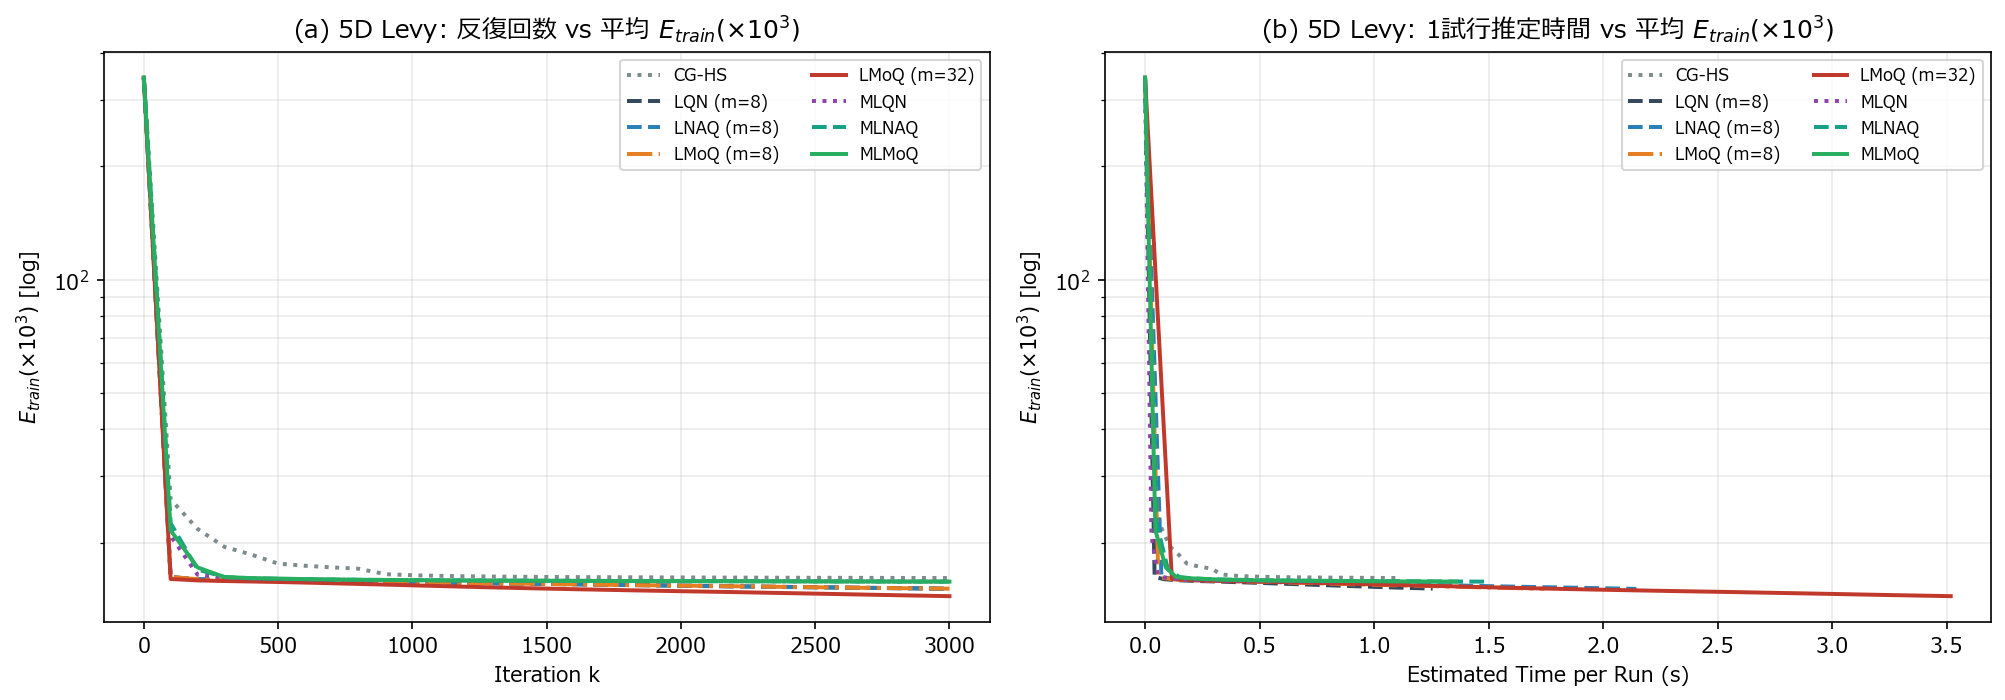

In [7]:
# 図3: 5次元 Levy 関数における LQN / LNAQ / LMoQ / CG / MLQN / MLNAQ / MLMoQ の収束曲線
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
plot_specs = [
    ('CG', 'CG-HS', '#7f8c8d', ':'),
    ('LQN_m8', 'LQN (m=8)', '#34495e', '--'),
    ('LNAQ_m8', 'LNAQ (m=8)', '#2980b9', '--'),
    ('LMoQ_m8', 'LMoQ (m=8)', '#e67e22', '-.'),
    ('LMoQ_m32', 'LMoQ (m=32)', '#c0392b', '-'),
    ('MLQN', 'MLQN', '#8e44ad', ':'),
    ('MLNAQ', 'MLNAQ', '#16a085', '--'),
    ('MLMoQ', 'MLMoQ', '#27ae60', '-'),
]
for key, lbl, col, ls in plot_specs:
    r = res_2b_map[key]
    axes[0].plot(r['rec_epochs'], np.clip(r['rec_means'] * 1e3, 1e-4, None), label=lbl, color=col, linestyle=ls, linewidth=1.9)
    est_t = r['rec_epochs'] * (r['per_iter_ms'] / 1000.0)
    axes[1].plot(est_t, np.clip(r['rec_means'] * 1e3, 1e-4, None), label=lbl, color=col, linestyle=ls, linewidth=1.9)

axes[0].set_yscale('log')
axes[0].set_title('(a) 5D Levy: 反復回数 vs 平均 $E_{train} (\\times 10^3)$')
axes[0].set_xlabel('Iteration k'); axes[0].set_ylabel('$E_{train} (\\times 10^3)$ [log]')
axes[0].legend(fontsize=8, ncol=2); axes[0].grid(alpha=0.25, which='both')

axes[1].set_yscale('log')
axes[1].set_title('(b) 5D Levy: 1試行推定時間 vs 平均 $E_{train} (\\times 10^3)$')
axes[1].set_xlabel('Estimated Time per Run (s)'); axes[1].set_ylabel('$E_{train} (\\times 10^3)$ [log]')
axes[1].legend(fontsize=8, ncol=2); axes[1].grid(alpha=0.25, which='both')

plt.tight_layout()
plt.savefig('../report/img/ex002_levy_lmoq_curves.png', dpi=150, bbox_inches='tight')
plt.show()